# Day 16 — رحلة تحليل بيانات السكري
**الأسبوع الثالث | الأربعاء 18 نوفمبر 2026**

الهدف: استكشاف العوامل المرتبطة بـ Outcome وتجهيز البيانات لتحليل تنبؤي لاحق، مع توثيق القرارات والأدلة. لا تتضمن المهمة تدريب نموذج أو إثبات أسباب الإصابة.

## Task 1 — فهم المشكلة والمصادر
المستفيد عيادة تريد فهم الأنماط داخل العينة لتوجيه دراسة الفحص المبكر. الهدف Outcome: القيمة 1 للفئة المصابة و0 لغير المصابة.

صفحة وصف البيانات: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

مصدر الملف المستخدم هنا: مرآة CSV دون عناوين للأعمدة: https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv

أضيفت أسماء الأعمدة بالترتيب المعروف وحفظت نسخة diabetes.csv؛ لم يتم تنزيل الملف من حساب Kaggle. العينة تضم 768 امرأة من أصول Pima بعمر 21 سنة فأكثر، ولذلك لا تعمم نتائجها تلقائيًا على مجتمع العيادة المحلي.

### قاموس الأعمدة
| العمود | المعنى |
|---|---|
| Pregnancies | عدد مرات الحمل |
| Glucose | جلوكوز البلازما بعد ساعتين من اختبار تحمل الجلوكوز |
| BloodPressure | الضغط الانبساطي |
| SkinThickness | سماكة ثنية الجلد |
| Insulin | إنسولين المصل بعد ساعتين |
| BMI | مؤشر كتلة الجسم |
| DiabetesPedigreeFunction | مؤشر تاريخ السكري العائلي |
| Age | العمر بالسنوات |
| Outcome | متغير الهدف الثنائي |


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 20)
df = pd.read_csv("diabetes.csv")
assert df.shape == (768, 9)
assert set(df.Outcome.unique()) == {0, 1}
display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Task 1.2 — أول نظرة على البيانات

In [2]:
print("Shape:", df.shape)
df.info()
display(df.describe().T)
display(pd.DataFrame({"dtype":df.dtypes.astype(str), "null_count":df.isna().sum(), "unique":df.nunique()}))
print("Exact duplicate rows:", df.duplicated().sum())
invalid_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = df[invalid_columns].eq(0).sum()
display(zero_counts.rename("invalid_zero_count").to_frame())

Shape: (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


,dtype,null_count,unique
Pregnancies,int64,0,17
Glucose,int64,0,136
BloodPressure,int64,0,47
SkinThickness,int64,0,51
Insulin,int64,0,186
BMI,float64,0,248
DiabetesPedigreeFunction,float64,0,517
Age,int64,0,52
Outcome,int64,0,2


,invalid_zero_count
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


البيانات تحتوي على **768 صفًا و9 أعمدة**، وعدد الصفوف المكررة تمامًا **0**. لا تظهر قيم NaN في الملف الخام، لكن هذا لا يعني اكتمال القياسات. يوجد **652** صفرًا في خمسة أعمدة قياس، موزعة على **376** صفًا. أبقيت صفر عدد مرات الحمل وصفر Outcome لأنهما قيمتان صحيحتان في سياقهما.

## Task 1.3 — EDA: الاستكشاف بالرسومات

Outcome                     1.000000
Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64


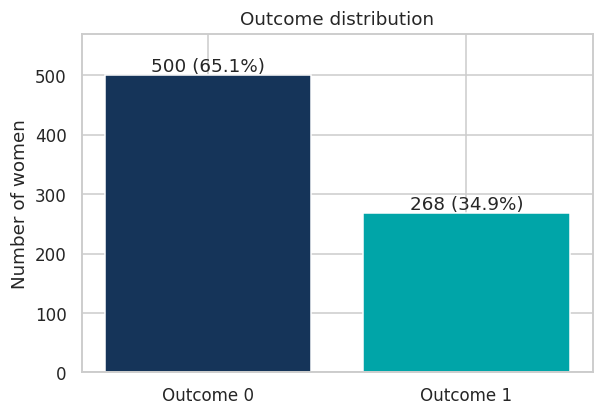

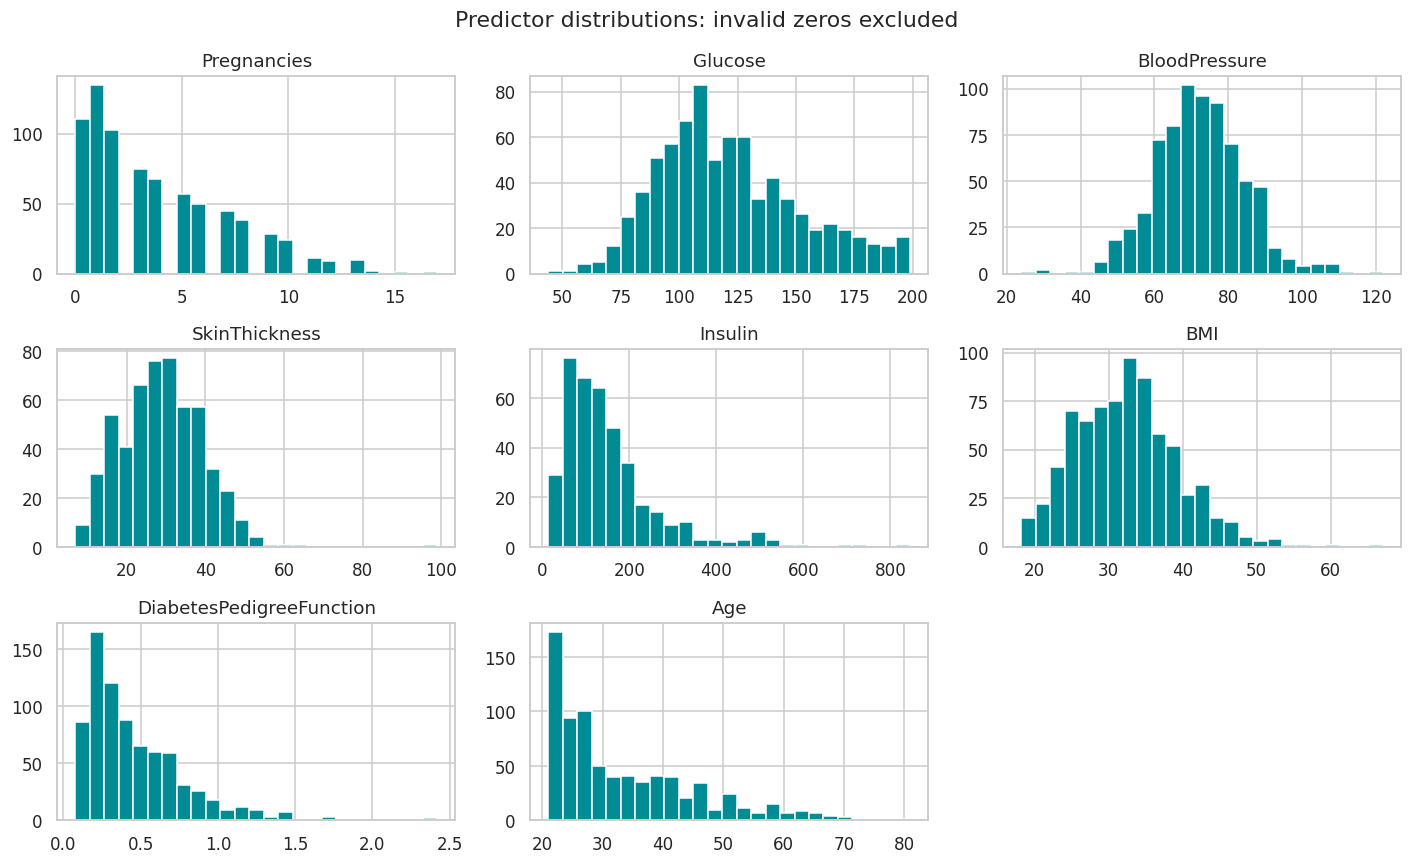

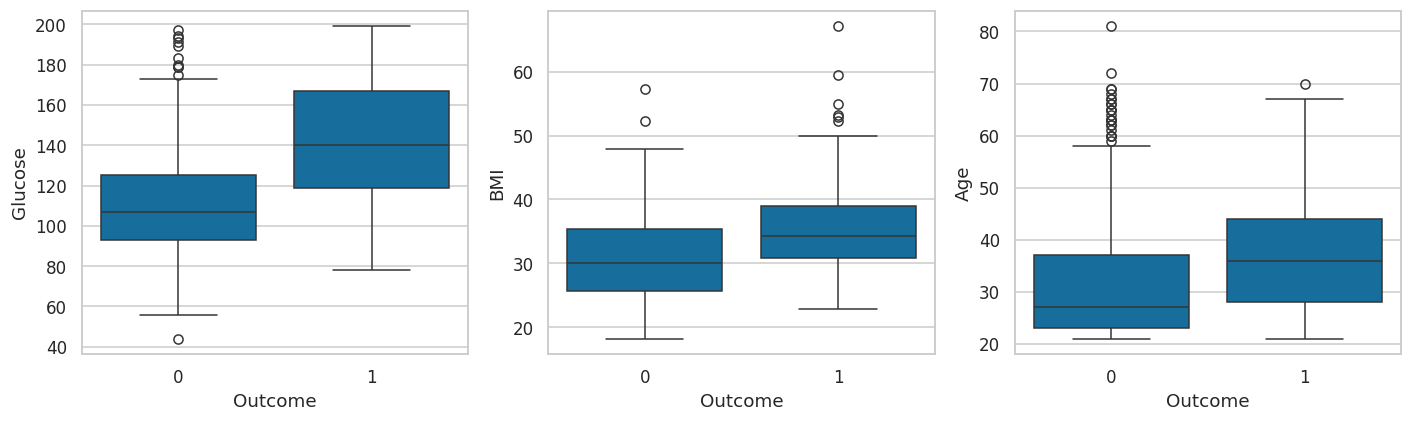

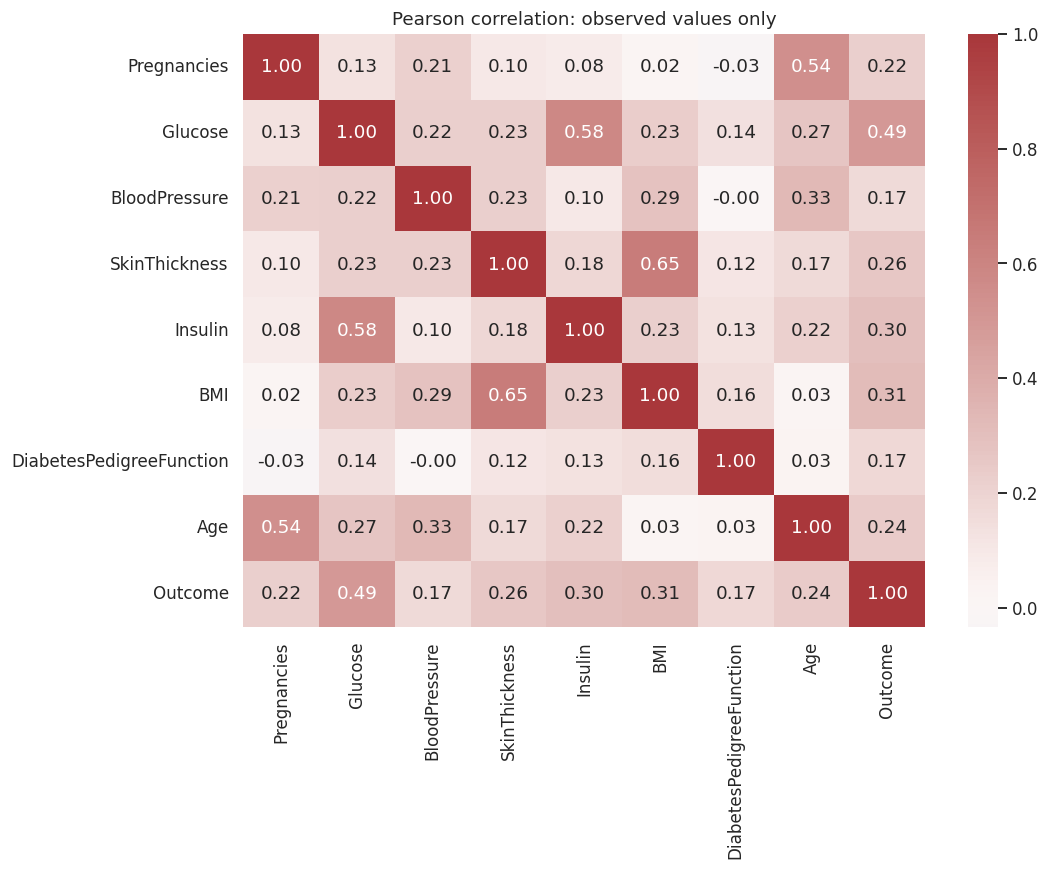

Glucose                      BMI                     Age         \
          count median        mean count median       mean count median   
Outcome                                                                   
0           497  107.0  110.643863   491   30.1  30.859674   500   27.0   
1           266  140.0  142.319549   266   34.3  35.406767   268   36.0   

                    
              mean  
Outcome             
0        31.190000  
1        37.067164

In [3]:
counts = df.Outcome.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(["Outcome 0", "Outcome 1"], counts.values, color=["#153459", "#00a5a8"])
for i,n in enumerate(counts.values): ax.text(i,n+6,f"{n} ({n/len(df):.1%})",ha="center")
ax.set(ylabel="Number of women",title="Outcome distribution", ylim=(0,570))
plt.show()
eda = df.copy()
eda[invalid_columns] = eda[invalid_columns].replace(0, np.nan)
eda.drop(columns="Outcome").hist(figsize=(13,8),bins=25,color="#008b95")
plt.suptitle("Predictor distributions: invalid zeros excluded")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,3,figsize=(13,4))
for col,ax in zip(["Glucose","BMI","Age"],axes):
    sns.boxplot(data=eda,x="Outcome",y=col,ax=ax)
plt.tight_layout();plt.show()
fig, ax = plt.subplots(figsize=(10,7))
sns.heatmap(eda.corr(),annot=True,fmt=".2f",cmap="vlag",center=0,ax=ax)
ax.set_title("Pearson correlation: observed values only")
plt.show()
display(eda.groupby("Outcome")[["Glucose","BMI","Age"]].agg(["count","median","mean"]))
display(eda.corr()["Outcome"].sort_values(ascending=False))

**قراءة الرسومات:** تضم الفئة 1 عدد **268 (34.9%)** والفئة 0 عدد **500**. لذلك توجد أغلبية للفئة 0، ويجب عدم الاكتفاء بالدقة وحدها عند بناء نموذج لاحقًا.

بعد استبعاد الأصفار غير الصالحة، ارتباط Glucose بالهدف **0.495**، وBMI **0.314**، وAge **0.238**. يظهر مخطط الصناديق اختلافًا في التوزيعات مع تداخل بين الفئتين؛ لا يمكن تحديد حالة كل امرأة من متغير منفرد. حساب الارتباط يستعمل الأزواج المرصودة فقط، وقد يختلف عددها بين الأعمدة.

## Task 1.4 — تنظيف البيانات وسجل القرارات

In [4]:
clean = eda.copy()
missing_flags = clean[invalid_columns].isna().astype("int8").add_suffix("_Missing")
missing_before = clean.isna().sum()
medians = clean[invalid_columns].median()
clean[invalid_columns] = clean[invalid_columns].fillna(medians)
log = pd.DataFrame({
    "column":invalid_columns,
    "zero_to_missing":zero_counts.values,
    "affected_percent":(zero_counts.values/len(df)*100).round(2),
    "fill_median":medians.values,
    "decision":["Replace zero with NaN; median fill; retain missing flag"]*5
})
display(log)
print("Rows retained:",len(clean))
print("Remaining missing values:",clean.isna().sum().sum())
# Audit unusual values; do not delete valid extremes automatically.
q1 = eda.drop(columns="Outcome").quantile(.25)
q3 = eda.drop(columns="Outcome").quantile(.75)
iqr = q3-q1
outlier_counts = ((eda[q1.index] < q1-1.5*iqr) | (eda[q1.index] > q3+1.5*iqr)).sum()
display(outlier_counts.rename("IQR_flag_count").to_frame())

Rows retained: 768
Remaining missing values: 0


,column,zero_to_missing,affected_percent,fill_median,decision
0,Glucose,5,0.65,117.0,Replace zero with NaN; median fill; retain mis...
1,BloodPressure,35,4.56,72.0,Replace zero with NaN; median fill; retain mis...
2,SkinThickness,227,29.56,29.0,Replace zero with NaN; median fill; retain mis...
3,Insulin,374,48.70,125.0,Replace zero with NaN; median fill; retain mis...
4,BMI,11,1.43,32.3,Replace zero with NaN; median fill; retain mis...


,IQR_flag_count
Pregnancies,4
Glucose,0
BloodPressure,14
SkinThickness,3
Insulin,24
BMI,8
DiabetesPedigreeFunction,29
Age,9


**القرار 1:** حولت الأصفار في Glucose (5) وBloodPressure (35) وSkinThickness (227) وInsulin (374) وBMI (11) إلى قيم مفقودة. هذه أصفار غير قابلة للتفسير كقياسات صالحة في هذا السياق.

**القرار 2:** احتفظت بجميع الصفوف وعوضت القياسات المفقودة بوسيط كل عمود، دون استخدام Outcome؛ الوسيط أقل تأثرًا بالقيم الكبيرة من المتوسط. أضفت مؤشرات نقص لأن غياب القياس قد يحمل معلومة عن طريقة جمع البيانات. هذا التعويض تبسيط استكشافي وقد يضغط التباين.

**القرار 3:** نسبة نقص Insulin هي **48.7%**؛ لذلك سأستبعد قياسه من النسخة الأساسية وأحتفظ بمؤشر نقصه للتجربة اللاحقة. حذف جميع الصفوف ذات النقص سيقلص العينة بشدة.

**القرار 4:** لم أحذف القيم التي يعلّمها IQR تلقائيًا؛ هذا فحص إحصائي وليس حكمًا بأن القيمة خطأ. احتفظت بالقياسات المتطرفة للمراجعة بدل تغييرها بلا دليل.

**ملاحظة منهجية:** ملف CSV النهائي صالح كناتج تجهيز للمهمة. عند تقييم نموذج مستقبلًا، يجب بدء التقسيم من البيانات الخام ثم تعلم الوسيط وأي اختيار قائم على الهدف من بيانات التدريب فقط، وتطبيقها على الاختبار؛ لا يستخدم CSV المعوض على كامل العينة لتقدير أداء غير متحيز.

## Task 1.5 — Feature Engineering: هندسة الخصائص

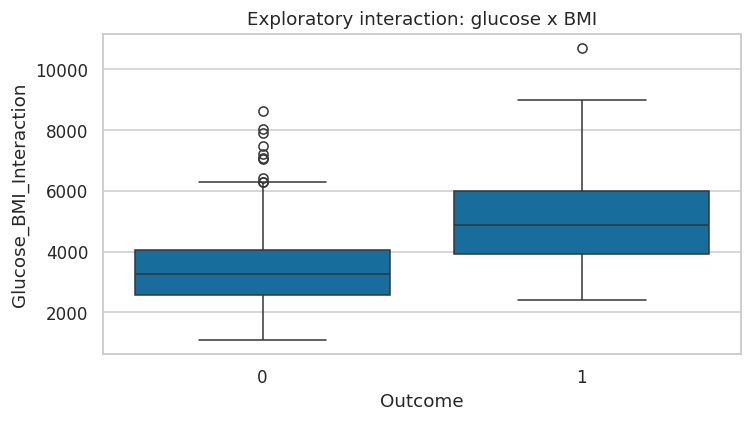

,Glucose_BMI_Interaction,Log_DiabetesPedigree
Outcome,,
0,3271.50,0.289680
1,4894.45,0.370873


In [5]:
engineered = pd.concat([clean,missing_flags],axis=1)
# Continuous transformation and interaction; no diagnostic thresholds.
engineered["Glucose_BMI_Interaction"] = engineered.Glucose * engineered.BMI
engineered["Log_DiabetesPedigree"] = np.log1p(engineered.DiabetesPedigreeFunction)
fig, ax = plt.subplots(figsize=(7,4))
sns.boxplot(data=engineered,x="Outcome",y="Glucose_BMI_Interaction",ax=ax)
ax.set_title("Exploratory interaction: glucose x BMI")
plt.tight_layout();plt.show()
display(engineered.groupby("Outcome")[["Glucose_BMI_Interaction","Log_DiabetesPedigree"]].median())

أضفت تفاعل Glucose × BMI لتمثيل اجتماعهما في خاصية واحدة؛ وسيطه **3271.5** للفئة 0 و**4969.6** للفئة 1. هذه خاصية استكشافية وليست مقياسًا طبيًا معتمدًا، ويحتاج نفعها إلى اختبار لاحق. كذلك أضفت log1p لمؤشر التاريخ العائلي لتقليل أثر الذيل الطويل مع الاحتفاظ بالترتيب. لم أضع تسميات تشخيصية أو حدودًا طبية مصطنعة.

## Task 1.6 — Feature Selection: اختيار الخصائص وحفظ البيانات

Saved: (768, 13)


,feature,decision,evidence
0,Pregnancies,Keep,"Observed predictor, missingness flag, or explo..."
1,Glucose,Keep,"Observed predictor, missingness flag, or explo..."
2,BloodPressure,Keep,"Observed predictor, missingness flag, or explo..."
3,SkinThickness,Exclude,High missingness: 29.6%; retain missing flag
4,Insulin,Exclude,High missingness: 48.7%; retain missing flag
5,BMI,Keep,"Observed predictor, missingness flag, or explo..."
6,DiabetesPedigreeFunction,Exclude,Keep log1p representation instead of duplicate...
7,Age,Keep,"Observed predictor, missingness flag, or explo..."
8,Outcome,Target,Keep as target; never a predictor
9,Glucose_Missing,Keep,"Observed predictor, missingness flag, or explo..."


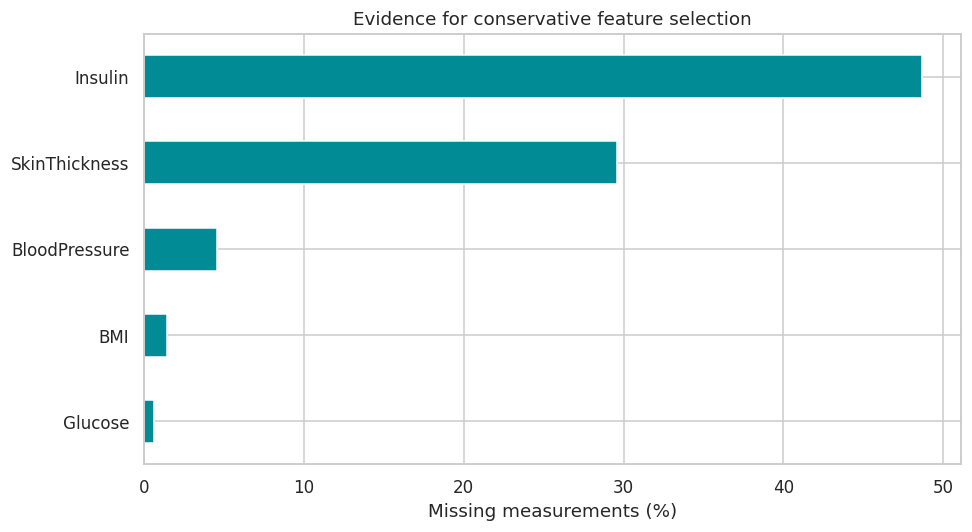

,Pregnancies,Glucose,BloodPressure,BMI,Age,Outcome,Glucose_Missing,BloodPressure_Missing,SkinThickness_Missing,Insulin_Missing,BMI_Missing,Glucose_BMI_Interaction,Log_DiabetesPedigree
0,6,148.0,72.0,33.6,50,1,0,0,0,1,0,4972.8,0.486738
1,1,85.0,66.0,26.6,31,0,0,0,0,1,0,2261.0,0.300845
2,8,183.0,64.0,23.3,32,1,0,0,1,1,0,4263.9,0.514021
3,1,89.0,66.0,28.1,21,0,0,0,0,0,0,2500.9,0.154436
4,0,137.0,40.0,43.1,33,1,0,0,0,0,0,5904.7,1.190279


In [6]:
decisions = []
for col in engineered.columns:
    if col == "Outcome":
        action,reason = "Target", "Keep as target; never a predictor"
    elif col in ["Insulin","SkinThickness"]:
        action,reason = "Exclude", f"High missingness: {missing_before[col]/len(df):.1%}; retain missing flag"
    elif col == "DiabetesPedigreeFunction":
        action,reason = "Exclude", "Keep log1p representation instead of duplicate representation"
    else:
        action,reason = "Keep", "Observed predictor, missingness flag, or exploratory engineered feature"
    decisions.append([col,action,reason])
selection = pd.DataFrame(decisions,columns=["feature","decision","evidence"])
display(selection)
fig,ax = plt.subplots(figsize=(9,5))
missing_before[invalid_columns].div(len(df)).mul(100).sort_values().plot.barh(ax=ax,color="#008b95")
ax.set(xlabel="Missing measurements (%)",title="Evidence for conservative feature selection")
plt.tight_layout();plt.show()
excluded = selection.loc[selection.decision.eq("Exclude"),"feature"].tolist()
model_ready = engineered.drop(columns=excluded)
assert len(model_ready)==768
assert model_ready.isna().sum().sum()==0
assert np.isfinite(model_ready.to_numpy()).all()
assert model_ready.Outcome.equals(df.Outcome)
model_ready.to_csv("diabetes_model_ready.csv",index=False)
log.to_csv("decision_log.csv",index=False)
selection.to_csv("feature_selection.csv",index=False)
print("Saved:", model_ready.shape)
display(model_ready.head())

استبعدت SkinThickness بسبب نقص **29.6%**، وInsulin بسبب نقص **48.7%**، مع الاحتفاظ بمؤشري النقص. استبدلت مؤشر التاريخ العائلي الأصلي بنسخته اللوغاريتمية لتجنب تكرار تمثيله. أبقيت بقية القياسات والتفاعل ومؤشرات النقص؛ هذا اختيار مبدئي قائم على جودة البيانات وقابلية التفسير، وليس ادعاءً بأنها المجموعة المثلى. لا أستبعد ضغط الدم بسبب ارتباط خطي ضعيف وحده. ينبغي مقارنة المجموعة المختارة بمجموعة أوسع بالتحقق المتقاطع داخل التدريب لاحقًا.

## Task 1.7 — النتائج والتوصيات
أهم إشارة خطية في هذه العينة هي Glucose، وتوجد أيضًا ارتباطات لـ BMI والعمر. أوصي بتحسين اكتمال القياسات قبل توسيع التحليل، ثم اختبار نموذج على تقسيم مستقل مع تقييم Recall وPrecision وF1 وROC-AUC ومعايرة الاحتمالات. قرار الفحص الطبي نفسه يحتاج تقييم الطبيب وبروتوكول العيادة، ولا يستند لهذا التحليل وحده.

## Task 2 — ملخص لطبيب العيادة

1. الهدف من التحليل هو وصف العوامل المرتبطة بنتيجة السكري داخل العينة، وليس تشخيص أفراد.

2. حللت 768 سجلًا لنساء من أصول Pima بعمر 21 سنة فأكثر.

3. بلغ عدد النتائج المصنفة 1 عدد 268، بنسبة 34.9%.

4. العامل الأول هو الجلوكوز: ارتباطه الخطي بالنتيجة 0.495 بعد استبعاد الأصفار غير الصالحة؛ يوضحه مخطط الصناديق وخريطة الارتباط.

5. العامل الثاني هو مؤشر كتلة الجسم: ارتباطه 0.314؛ يوضحه مخطط BMI حسب النتيجة.

6. العامل الثالث هو العمر: ارتباطه 0.238؛ يوضحه مخطط العمر حسب النتيجة.

7. أكبر مشكلة جودة هي نقص الإنسولين المخفي في صورة أصفار: 374 سجلًا، أي 48.7%.

8. حولت الأصفار غير الصالحة إلى نقص، وعوضت بالوسيط دون الاستعانة بنتيجة السكري.

9. احتفظت بمؤشرات النقص واستبعدت قياسي الإنسولين وسماكة الجلد من النسخة الأساسية بسبب نقصهما المرتفع.

10. التعويض بالوسيط لا يعيد القياسات الحقيقية، وقد يغير التوزيع؛ لذلك يلزم توثيقه ومراجعة حساسية النتائج.

11. التوصية العملية للعيادة هي مراجعة اكتمال إدخال قياسات الجلوكوز وBMI وبقية القياسات وتوحيد تسجيل الغياب بدل الصفر.

12. لا تثبت هذه البيانات أن زيادة عامل ما تسبب السكري، ولا تحدد أثر علاجه أو تخفيضه.

13. النتائج وصفية لعينة محددة، ويجب اختبار صلاحيتها على بيانات محلية مستقلة قبل استخدامها لدعم القرار.